# TRANSFORMER FOR AV2 DATASET PROJECT

## Useful Imports & Definitions

In [ ]:
import os, csv, math, random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

current_script_path = Path(__file__).resolve()
parent_dir = current_script_path.parent
array_folder= parent_dir/ "model_arrays"
latents_folder= current_script_path/"latents"

## Defining train and test dataset .npy file locations
TRAIN_PATH = array_folder/"train_array.npy"
TEST_PATH = array_folder/"test_array.npy"

## Creates a directory and saves the transformer's statistics
OUTPUT_DIR = latents_folder

## Model Hyperparameters
D_MODEL = 128
NHEAD = 4 # For Multi-Head Attention
NUM_LAYERS = 3 # Layers of Transformers
FF_DIM = 256 # Feed-Forward Network dimension
DROPOUT = 0.1
LATENT_DIM = 8 # The "d", dimension of latent space. From 2 to 16

BATCH_SIZE = 256 # Items per batch of train
EPOCHS = 15 # How many epochs to train the transformer
PATIENCE = 5 # After "PATIENCE" epochs of no better loss, terminate training
LR = 1e-3 # Learning Rate
MIN_LR = 1e-5
WEIGHT_DECAY = 1e-5 # The Optimizer's Weight Decay
VAL_SPLIT = 0.1 # Train-Val Split
SEED = 42 # Set seed for random split of train-val
DEVICE = "cuda" if torch.cuda.is_available() else "cpu" # Train on GPU if possible
CLUSTER_RANGE = range(2, 9) # Check k = 2 to 9 in KMeans after training

Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

## Load numpy arrays
train_array = np.load(TRAIN_PATH)
test_array = np.load(TEST_PATH)
assert train_array.ndim == 3 and test_array.ndim == 3, "Expected [N, T, F] arrays"

N_TRAIN, SEQ_LEN, INPUT_DIM = train_array.shape
assert test_array.shape[1:] == (SEQ_LEN, INPUT_DIM)

## Print basic information about dataset and device available
print("Train shape:", train_array.shape)
print("Test shape :", test_array.shape)
print("Device     :", DEVICE)

Train shape: (65790, 50, 2)
Test shape : (7311, 50, 2)
Device     : cuda


## The Model

### The Dataset

In [ ]:
class TrajectoryDataset(Dataset):
    def __init__(self, array):
        self.x = torch.tensor(array, dtype=torch.float32)
    def __len__(self):
        return len(self.x)
    def __getitem__(self, idx):
        return self.x[idx]

### Helpers

In [ ]:
def scaled_self_attention(q, k, v):
    d_k = q.shape[-1]
    logits = torch.matmul(q, k.transpose(-2, -1))
    logits = logits / math.sqrt(d_k)
    attention = nn.functional.softmax(logits, dim=-1) #
    output = torch.matmul(attention, v)
    return output, attention

def split_train_val(array, val_split=0.1, seed=42):
    idx = np.arange(len(array))
    rng = np.random.default_rng(seed)
    rng.shuffle(idx)
    val_size = int(len(array) * val_split)
    val_idx = idx[:val_size]
    train_idx = idx[val_size:]
    return array[train_idx], array[val_idx]

def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, total_count = 0.0, 0
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            recon, _ = model(batch)
            vel_target = batch[:, 1:, :] - batch[:, :-1, :]
            vel_recon  = recon[:, 1:, :] - recon[:, :-1, :]
            loss = criterion(vel_recon, vel_target)
            total_loss += loss.item() * batch.size(0)
            total_count += batch.size(0)
    return total_loss / total_count

def extract_latents(model, loader, device):
    model.eval()
    latents = []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            z = model.encode(batch)
            latents.append(z.cpu().numpy())
    return np.concatenate(latents, axis=0)

### The Transformer

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()

        # create matrix Π, representing the positional encoding for max_len inputs
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)   # [5000, 1]
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)

        # register_buffer => Tensor which is not a parameter, but should be part of the modules state.
        # Used for tensors that need to be on the same device as the module.
        # persistent=False tells PyTorch to not add the buffer to the state dict (e.g. when we save the model)
        self.register_buffer('pe', pe, persistent=False)

    def forward(self, x):
        x = x + self.pe[:, :x.size(1)]
        return x

class MHA(nn.Module):
    def __init__(self, input_dim, embed_dim, num_heads=NHEAD):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        self.qkv_proj = nn.Linear(input_dim, 3 * embed_dim)
        self.out_proj = nn.Linear(embed_dim, input_dim)

    def forward(self, x):
        B, N, D = x.shape[0], x.shape[1], self.embed_dim

        # x = self.pe(x)
        q, k, v = self.qkv_proj(x).chunk(3, dim=-1)  # each (B, N, D)

        # Split into heads: (B, num_heads, N, head_dim) -> (B*num_heads, N, head_dim)
        def split_heads(t):
            return t.view(B, N, self.num_heads, self.head_dim).transpose(1, 2).reshape(B * self.num_heads, N, self.head_dim)

        q, k, v = split_heads(q), split_heads(k), split_heads(v)

        out, attn_weights = scaled_self_attention(q, k, v)  # (B*H, N, head_dim), (B*H, N, N)

        # Merge heads back: (B*H, N, head_dim) -> (B, N, D)
        out = out.reshape(B, self.num_heads, N, self.head_dim).transpose(1, 2).reshape(B, N, D)

        # Average attention weights across heads for visualisation: (B, N, N)
        attn_weights = attn_weights.reshape(B, self.num_heads, N, N).mean(dim=1)

        return self.out_proj(out), attn_weights

class TransformerMHA(nn.Module):
    def __init__(self, input_dim, embed_dim, num_layers, latent_dim, ff_dim=256):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, embed_dim)

        ## Positional Encoding moved here
        self.pe = PositionalEncoding(embed_dim)

        # ModuleList instead of single instance
        self.norm1 = nn.ModuleList([nn.LayerNorm(embed_dim) for _ in range(num_layers)])
        self.attn  = nn.ModuleList([MHA(embed_dim, embed_dim) for _ in range(num_layers)])
        self.norm2 = nn.ModuleList([nn.LayerNorm(embed_dim) for _ in range(num_layers)])
        self.ff    = nn.ModuleList([
            nn.Sequential(nn.Linear(embed_dim, ff_dim), nn.ReLU(), nn.Linear(ff_dim, embed_dim))
            for _ in range(num_layers)
        ])

        self.enc_to_latent = nn.Linear(embed_dim, latent_dim)
        self.latent_to_dec = nn.Linear(latent_dim, embed_dim)
        self.output_proj = nn.Linear(embed_dim, input_dim)

    def _run_layers(self, x):
        attn_weights = None
        for norm1, attn, norm2, ff in zip(self.norm1, self.attn, self.norm2, self.ff):
            attn_out, attn_weights = attn(norm1(x))
            x = x + attn_out
            x = x + ff(norm2(x))
        return x, attn_weights

    # Encode batch to latent vector
    def encode(self, x):
        x = self.pe(self.input_proj(x))
        for norm1, attn, norm2, ff in zip(self.norm1, self.attn, self.norm2, self.ff):
            attn_out, _ = attn(norm1(x))
            x = x + attn_out
            x = x + ff(norm2(x))
        return self.enc_to_latent(x.mean(dim=1))

    ## Forward pass, takes trajectories and returns reconstructed trajectories
    def forward(self, x):
        N = x.shape[1]
        z = self.encode(x)
        h = self.latent_to_dec(z).unsqueeze(1).expand(-1, N, -1)
        h = self.pe(h)
        for norm1, attn, norm2, ff in zip(self.norm1, self.attn, self.norm2, self.ff):
            attn_out, attn_weights = attn(norm1(h))
            h = h + attn_out
            h = h + ff(norm2(h))
        return self.output_proj(h), attn_weights


## Training the model

In [ ]:
## Split train and validation data randomly
train_data, val_data = split_train_val(train_array, val_split=VAL_SPLIT, seed=SEED)

## Load the data from the TrajectoryDataset class
train_loader = DataLoader(TrajectoryDataset(train_data), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TrajectoryDataset(val_data), batch_size=BATCH_SIZE, shuffle=False)
train_full_loader = DataLoader(TrajectoryDataset(train_array), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TrajectoryDataset(test_array), batch_size=BATCH_SIZE, shuffle=False)

## The Model
model = TransformerMHA(
    input_dim  = INPUT_DIM,
    embed_dim  = D_MODEL,
    num_layers = NUM_LAYERS,
    latent_dim = LATENT_DIM,
    ff_dim     = FF_DIM,
).to(DEVICE)

## Use MSE Loss as objective
criterion = nn.MSELoss()

## Use of AdamW as optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3, min_lr=MIN_LR)

best_val_loss = float("inf")
best_epoch = 0
wait = 0
history = []

## The training loop
for epoch in range(1, EPOCHS + 1):
    model.train() # Set the model in train mode
    total_loss, total_count = 0.0, 0 # Start calculating losses
    # Take the data in batches
    for batch in train_loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()
        recon, _ = model(batch)
        vel_target = batch[:, 1:, :] - batch[:, :-1, :] # The target (dx, dy), taken from the dataset
        vel_recon  = recon[:, 1:, :] - recon[:, :-1, :] # The reconstructed (dx, dy), taken from training
        loss = criterion(vel_recon, vel_target) # The objective; Minimize velocity
        loss.backward() # Backward pass
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0) # Clips the gradient so that problematic batches dont cause huge issues
        optimizer.step() # Step
        total_loss += loss.item() * batch.size(0) # Get the loss from this batch
        total_count += batch.size(0) # Increase countextract_latents

    train_loss = total_loss / total_count # Average train loss for this epoch
    val_loss = evaluate(model, val_loader, criterion, DEVICE) # Evaluate loss in validation
    scheduler.step(val_loss)
    lr_now = optimizer.param_groups[0]["lr"] # Read current learning rate
    history.append((epoch, train_loss, val_loss, lr_now)) # Keep history
    print(f"Epoch {epoch:03d} | train={train_loss:.6f} | val={val_loss:.6f} | lr={lr_now:.6f}") # Print results

    ## Check patience
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        wait = 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Early stopping triggered")
            break

# Evaluate testing loss and print valuable information
test_loss = evaluate(model, test_loader, criterion, DEVICE)
print("Best epoch:", best_epoch)
print("Best val loss:", best_val_loss)
print("Test loss:", test_loss)

Epoch 001 | train=0.000057 | val=0.000004 | lr=0.001000
Epoch 002 | train=0.000004 | val=0.000004 | lr=0.001000
Epoch 003 | train=0.000004 | val=0.000004 | lr=0.001000
Epoch 004 | train=0.000004 | val=0.000004 | lr=0.001000
Epoch 005 | train=0.000004 | val=0.000003 | lr=0.001000
Epoch 006 | train=0.000003 | val=0.000002 | lr=0.001000
Epoch 007 | train=0.000002 | val=0.000002 | lr=0.001000
Epoch 008 | train=0.000002 | val=0.000002 | lr=0.001000
Epoch 009 | train=0.000002 | val=0.000001 | lr=0.001000
Epoch 010 | train=0.000001 | val=0.000001 | lr=0.001000
Epoch 011 | train=0.000001 | val=0.000001 | lr=0.001000
Epoch 012 | train=0.000001 | val=0.000001 | lr=0.001000
Epoch 013 | train=0.000001 | val=0.000001 | lr=0.001000
Epoch 014 | train=0.000001 | val=0.000001 | lr=0.001000
Epoch 015 | train=0.000001 | val=0.000001 | lr=0.001000
Best epoch: 15
Best val loss: 7.105009405110058e-07
Test loss: 7.011698861580692e-07


### Plot Training Curve

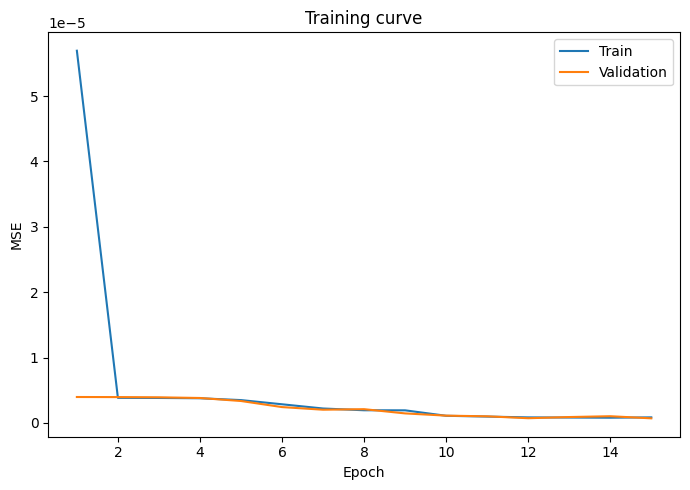

Saved outputs to transformer_output


In [ ]:
## Extract and save latents from the loader
train_latents = extract_latents(model, train_full_loader, DEVICE)
test_latents = extract_latents(model, test_loader, DEVICE)
np.save(os.path.join(OUTPUT_DIR, f"train_latents_{LATENT_DIM}.npy"), train_latents)
np.save(os.path.join(OUTPUT_DIR, f"test_latents_{LATENT_DIM}.npy"), test_latents)

## Save loss history to a .csv file
with open(os.path.join(OUTPUT_DIR, "loss_history.csv"), "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["epoch", "train_loss", "val_loss", "lr"])
    writer.writerows(history)

epochs = [x[0] for x in history]
train_losses = [x[1] for x in history]
val_losses = [x[2] for x in history]

plt.figure(figsize=(7, 5))
plt.plot(epochs, train_losses, label="Train")
plt.plot(epochs, val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training curve")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_curve.png"), dpi=180)
plt.show()

with open(os.path.join(OUTPUT_DIR, "run_summary.txt"), "w") as f:
    f.write(f"train_shape={train_array.shape}\n")
    f.write(f"test_shape={test_array.shape}\n")
    f.write(f"seq_len={SEQ_LEN}\n")
    f.write(f"input_dim={INPUT_DIM}\n")
    f.write(f"latent_dim={LATENT_DIM}\n")
    f.write(f"best_epoch={best_epoch}\n")
    f.write(f"best_val_loss={best_val_loss:.8f}\n")
    f.write(f"test_recon_mse={test_loss:.8f}\n")

print("Saved outputs to", OUTPUT_DIR)

## Test the model on Noizy data

In [ ]:
## New test loader with noizy data
noizy_test_loader = DataLoader(TrajectoryDataset(np.load("noisy_test_array_encoder_001.npy")), batch_size=BATCH_SIZE, shuffle=False)

## Test with noizy data
noizy_test_loss = evaluate(model, noizy_test_loader, criterion, DEVICE)

## Extract and save latents
noizy_test_latents = extract_latents(model, noizy_test_loader, DEVICE)
np.save(os.path.join(OUTPUT_DIR, "noizy_test_latents.npy"), noizy_test_latents)